In [31]:
# Investigate the bias-variance tradeoff using polynomial regression on the California Housing
# dataset. Plot the training and validation errors for various polynomial degrees and discuss
# the tradeoff between bias and variance.
# Tasks:
# ● Load and preprocess the California Housing dataset.
# ● Implement polynomial regression with varying degrees.
# ● Plot training and validation errors for each degree.
# ● Discuss the bias-variance tradeoff and its impact on model performance.

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [33]:
data = fetch_california_housing(as_frame = True)
data = data.frame
x = data[['MedInc']]
y = data['MedHouseVal']
data

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [34]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 42)
train_errors , val_errors = [],[]
degrees = [i for i in range(1,11)]
degrees

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [35]:
# Polynomial Regression
for degree in degrees:
    poly = PolynomialFeatures(degree = degree)
    x_train_poly = poly.fit_transform(x_train)
    x_test_poly = poly.transform(x_test)
    model = LinearRegression()
    model.fit(x_train_poly,y_train)
    train_pred = model.predict(x_train_poly)
    val_pred = model.predict(x_test_poly)
    train_errors.append(mean_squared_error(y_train,train_pred))
    val_errors.append(mean_squared_error(y_test,val_pred))

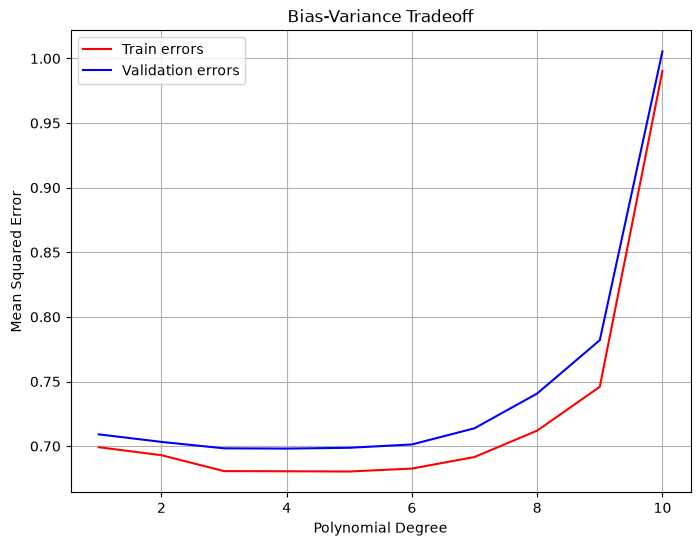

In [36]:
# Plot (Degree vs Errors)
plt.figure(figsize=(8,6))
plt.plot(degrees,train_errors,color = 'red',label = 'Train errors')
plt.plot(degrees,val_errors,color = 'blue',label = 'Validation errors')
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Bias-Variance Tradeoff")
plt.legend()
plt.grid()
plt.show()